In [12]:
!pip install evaluate bert_score rouge_score

In [13]:
import pandas as pd
import numpy as np
import csv
import matplotlib.pyplot as plt
import seaborn as sns
import ast

In [14]:
oab_df = pd.read_csv('/kaggle/input/oab-2024/oab_2024.csv')
oab_df

,numero,pergunta,opcoes
0,1,Determinada operação de combate à corrupção co...,"['A) A medida cautelar decretada é inválida, u..."
1,2,"O advogado Antônio Carlos ajuizou, em favor de...",['A) A responsabilidade de Antônio Carlos e Ce...
2,3,"Roberto Silva, advogado e sócio fundador da so...",['A) É impositiva a exclusão de Roberto Silva ...
3,4,A advogada Nina exerce função na diretoria do ...,['A) Nina não deve depor sobre os fatos que so...
4,5,"Roberto Gil, professor de Direito Administrati...",['A) O exercício da advocacia é incompatível c...
...,...,...,...
75,76,Em sede de reclamação trabalhista você advoga ...,"['A) Caberá recurso adesivo.', 'B) Caberá recu..."
76,77,Em uma reclamação trabalhista requerendo a res...,['A) A empresa deverá arcar com os honorários ...
77,78,Foi protocolizada petição de homologação de ac...,"['A) Não é possível a homologação, porque as p..."
78,79,"Em 2024, o Juiz proferiu sentença ilíquida em ...",['A) Você deverá sustentar em contraminuta aos...


In [15]:
lbl_24 = pd.read_csv('/kaggle/input/labels-oab/labels_oab_2024.csv', header=None)
lbl_24

,0
0,﻿D
1,B
2,D
3,A
4,D
...,...
75,A
76,D
77,A
78,D


In [16]:
oab_df = oab_df.join(lbl_24)

In [17]:
oab_df = oab_df.rename(columns={0: 'resposta'})
oab_df

,numero,pergunta,opcoes,resposta
0,1,Determinada operação de combate à corrupção co...,"['A) A medida cautelar decretada é inválida, u...",﻿D
1,2,"O advogado Antônio Carlos ajuizou, em favor de...",['A) A responsabilidade de Antônio Carlos e Ce...,B
2,3,"Roberto Silva, advogado e sócio fundador da so...",['A) É impositiva a exclusão de Roberto Silva ...,D
3,4,A advogada Nina exerce função na diretoria do ...,['A) Nina não deve depor sobre os fatos que so...,A
4,5,"Roberto Gil, professor de Direito Administrati...",['A) O exercício da advocacia é incompatível c...,D
...,...,...,...,...
75,76,Em sede de reclamação trabalhista você advoga ...,"['A) Caberá recurso adesivo.', 'B) Caberá recu...",A
76,77,Em uma reclamação trabalhista requerendo a res...,['A) A empresa deverá arcar com os honorários ...,D
77,78,Foi protocolizada petição de homologação de ac...,"['A) Não é possível a homologação, porque as p...",A
78,79,"Em 2024, o Juiz proferiu sentença ilíquida em ...",['A) Você deverá sustentar em contraminuta aos...,D


In [18]:
import pandas as pd
import ast

# Converter a coluna 'opcoes' de string para lista
oab_df['opcoes'] = oab_df['opcoes'].apply(ast.literal_eval)

# Função para extrair a alternativa correta (versão corrigida)
def extrair_alternativa_correta(row):
    # Limpeza agressiva da resposta
    letra_correta = str(row['resposta']).strip().upper()
    letra_correta = ''.join([c for c in letra_correta if c.isalpha()])  # Mantém apenas letras
    
    opcoes = {}
    for opcao in row['opcoes']:
        # Limpeza agressiva da opção
        letra_opcao = opcao.strip().upper()
        letra_opcao = letra_opcao.split(')')[0].split('.')[0].split(':')[0]  # Trata "A:", "A.", etc
        letra_opcao = ''.join([c for c in letra_opcao if c.isalpha()])  # Remove não-letras
        opcoes[letra_opcao] = opcao
    
    return opcoes.get(letra_correta, "Alternativa não encontrada")

# Adicionar coluna com o texto da alternativa correta
oab_df['alternativa_correta'] = oab_df.apply(extrair_alternativa_correta, axis=1)

In [19]:
oab_df

,numero,pergunta,opcoes,resposta,alternativa_correta
0,1,Determinada operação de combate à corrupção co...,"[A) A medida cautelar decretada é inválida, um...",﻿D,"D) A medida cautelar decretada é válida, e as ..."
1,2,"O advogado Antônio Carlos ajuizou, em favor de...",[A) A responsabilidade de Antônio Carlos e Cel...,B,B) Não há responsabilidade solidária entre Cel...
2,3,"Roberto Silva, advogado e sócio fundador da so...",[A) É impositiva a exclusão de Roberto Silva d...,D,"D) Embora incompatível com a advocacia, o exer..."
3,4,A advogada Nina exerce função na diretoria do ...,[A) Nina não deve depor sobre os fatos que sou...,A,A) Nina não deve depor sobre os fatos que soub...
4,5,"Roberto Gil, professor de Direito Administrati...",[A) O exercício da advocacia é incompatível co...,D,"D) Embora, em regra, os servidores da administ..."
...,...,...,...,...,...
75,76,Em sede de reclamação trabalhista você advoga ...,"[A) Caberá recurso adesivo., B) Caberá recurso...",A,A) Caberá recurso adesivo.
76,77,Em uma reclamação trabalhista requerendo a res...,[A) A empresa deverá arcar com os honorários d...,D,D) O réu será condenado a pagar os honorários ...
77,78,Foi protocolizada petição de homologação de ac...,"[A) Não é possível a homologação, porque as pa...",A,"A) Não é possível a homologação, porque as par..."
78,79,"Em 2024, o Juiz proferiu sentença ilíquida em ...",[A) Você deverá sustentar em contraminuta aos ...,D,D) Está preclusa a arguição de matérias que im...


In [20]:
claude_resp = pd.read_csv('/kaggle/input/models-resp/claude_resp.csv')
ds_resp = pd.read_csv('/kaggle/input/models-resp/ds_resp.csv')
gpt_resp = pd.read_csv('/kaggle/input/models-resp/gpt_resp.csv')
llama_resp = pd.read_csv('/kaggle/input/models-resp/llama_resp.csv')
mixtral_resp = pd.read_csv('/kaggle/input/models-resp/mixtral_resp.csv')
qwen_resp = pd.read_csv('/kaggle/input/models-resp/qwen_resp.csv')

In [21]:
ds_resp

,numero,resposta
0,1,"D) A medida cautelar decretada é válida, e as ..."
1,2,B) Não há responsabilidade solidária entre Cel...
2,3,"D) Embora incompatível com a advocacia, o exer..."
3,4,A) Nina não deve depor sobre os fatos que soub...
4,5,"D) Embora, em regra, os servidores da administ..."
...,...,...
75,76,"D) Não há medida a ser adotada, transitando em..."
76,77,B) A Justiça arcará com os honorários do perit...
77,78,"A) Não é possível a homologação, porque as par..."
78,79,D) Está preclusa a arguição de matérias que im...


In [22]:
from evaluate import load
bertscore = load("bertscore")
predictions_ds = ds_resp['resposta']
references = oab_df['alternativa_correta']
bert_f1_results_ds = bertscore.compute(predictions=predictions_ds, references=references, lang="pt")

model.safetensors:  62%|######1   | 440M/714M [00:00<?, ?B/s]

In [23]:
predictions_claude = claude_resp['resposta']
bert_f1_results_claude = bertscore.compute(predictions=predictions_claude, references=references, lang="pt")

In [24]:
predictions_gpt = gpt_resp['resposta_correta']
bert_f1_results_gpt = bertscore.compute(predictions=predictions_gpt, references=references, lang="pt")

In [25]:
predictions_llama = llama_resp['resposta_correta']
bert_f1_results_llama = bertscore.compute(predictions=predictions_llama, references=references, lang="pt")

In [26]:
predictions_mixtral = mixtral_resp['resposta_correta']
bert_f1_results_mixtral = bertscore.compute(predictions=predictions_mixtral, references=references, lang="pt")

In [27]:
predictions_qwen = qwen_resp['resposta_correta']
bert_f1_results_qwen = bertscore.compute(predictions=predictions_qwen, references=references, lang="pt")

In [28]:
print('ds:')
ds_metrics = pd.DataFrame.from_dict(bert_f1_results_ds)
ds_metrics['f1'].mean()

ds:


0.8716187253594398

In [29]:
print('claude:')
claude_metrics = pd.DataFrame.from_dict(bert_f1_results_claude)
claude_metrics['f1'].mean()

claude:


0.8946345992386341

In [30]:
print('gpt:')
gpt_metrics = pd.DataFrame.from_dict(bert_f1_results_gpt)
gpt_metrics['f1'].mean()

gpt:


0.7966467030346394

In [31]:
print('llama:')
llama_metrics = pd.DataFrame.from_dict(bert_f1_results_llama)
llama_metrics['f1'].mean()

llama:


0.8427190981805325

In [32]:
print('mixtral:')
mixtral_metrics = pd.DataFrame.from_dict(bert_f1_results_mixtral)
mixtral_metrics['f1'].mean()

mixtral:


0.791812165081501

In [33]:
print('qwen:')
qwen_metrics = pd.DataFrame.from_dict(bert_f1_results_qwen)
qwen_metrics['f1'].mean()

qwen:


0.8320579662919044

In [34]:
rouge = load('rouge')
rouge_results_ds = rouge.compute(predictions=predictions_ds, references=references, use_aggregator=False)
rouge_results_claude = rouge.compute(predictions=predictions_claude, references=references, use_aggregator=False)
rouge_results_gpt = rouge.compute(predictions=predictions_gpt, references=references, use_aggregator=False)
rouge_results_llama = rouge.compute(predictions=predictions_llama, references=references, use_aggregator=False)
rouge_results_mixtral = rouge.compute(predictions=predictions_mixtral, references=references, use_aggregator=False)
rouge_results_qwen = rouge.compute(predictions=predictions_qwen, references=references, use_aggregator=False)

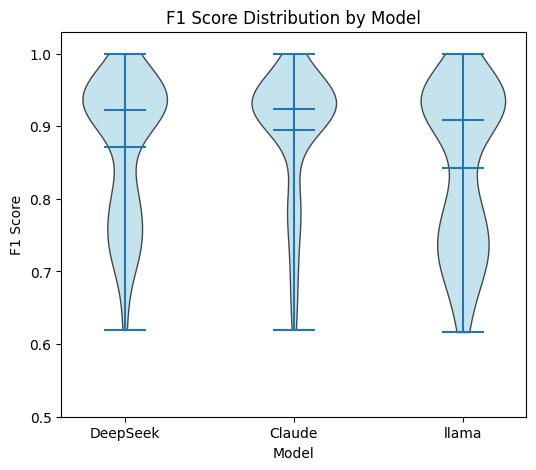

In [35]:
# Criando o gráfico de violino com Matplotlib
fig, ax = plt.subplots(figsize=(6, 5))

# Plotando o gráfico de violino (código existente)
parts = ax.violinplot([bert_f1_results_ds['f1'], bert_f1_results_claude['f1'], bert_f1_results_llama['f1']], positions=[0, 1, 2], showmeans=True, showmedians=True)

# Personalização (código existente)
for pc in parts['bodies']:
    pc.set_facecolor('lightblue')
    pc.set_edgecolor('black')
    pc.set_alpha(0.7)

ax.set_ylim(0.5, 1.03)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["DeepSeek", "Claude", "llama"])
ax.set_xlabel("Model")
ax.set_ylabel("F1 Score")
ax.set_title("F1 Score Distribution by Model")

# Salvar a figura antes de exibir
plt.savefig('f1_distribution1.png')  # Altere o nome/formato se necessário

# Exibir gráfico
plt.show()

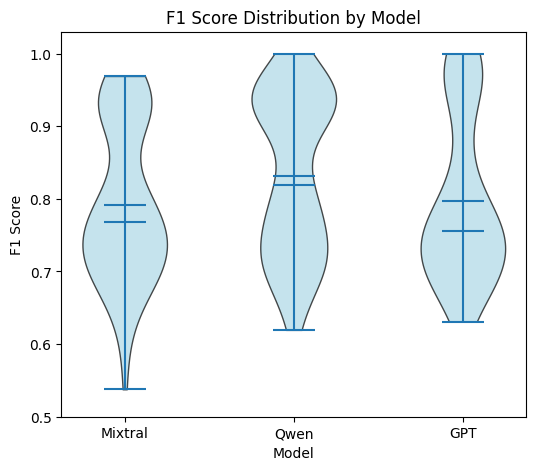

In [36]:
# Criando o gráfico de violino com Matplotlib
fig, ax = plt.subplots(figsize=(6, 5))

# Plotando o gráfico de violino
parts = ax.violinplot([bert_f1_results_mixtral['f1'], bert_f1_results_qwen['f1'], bert_f1_results_gpt['f1']], positions=[0, 1, 2], showmeans=True, showmedians=True)

# Personalizando cores (opcional)
for pc in parts['bodies']:
    pc.set_facecolor('lightblue')  # Cor do violino
    pc.set_edgecolor('black')
    pc.set_alpha(0.7)

ax.set_ylim(0.5, 1.03)
# Ajustando os rótulos do eixo X
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["Mixtral", "Qwen", "GPT"])

# Personalizando o gráfico
ax.set_xlabel("Model")
ax.set_ylabel("F1 Score")
ax.set_title("F1 Score Distribution by Model")

# Salvar a figura antes de exibir
plt.savefig('f1_distribution2.png')  # ⬅️ Linha adicionada

# Exibir gráfico
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

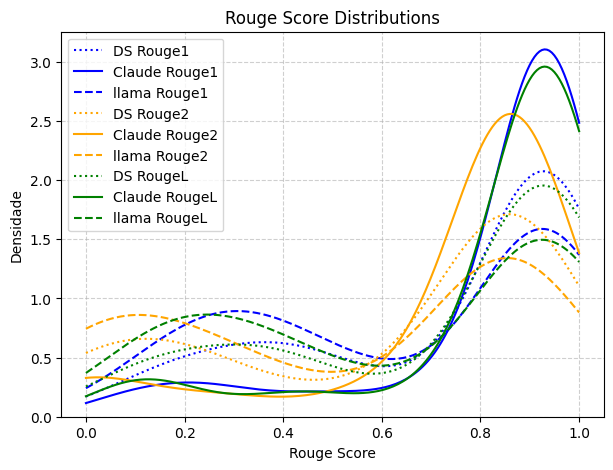

In [37]:
# Criando o gráfico
plt.figure(figsize=(7, 5))

# Estilos de linhas
sns.kdeplot(rouge_results_ds['rouge1'], linestyle='dotted', color='blue', label="DS Rouge1", clip=(0, 1))
sns.kdeplot(rouge_results_claude['rouge1'], linestyle='solid', color='blue', label="Claude Rouge1", clip=(0, 1))
sns.kdeplot(rouge_results_llama['rouge1'], linestyle='dashed', color='blue', label="llama Rouge1", clip=(0, 1))

sns.kdeplot(rouge_results_ds['rouge2'], linestyle='dotted', color='orange', label="DS Rouge2", clip=(0, 1))
sns.kdeplot(rouge_results_claude['rouge2'], linestyle='solid', color='orange', label="Claude Rouge2", clip=(0, 1))
sns.kdeplot(rouge_results_llama['rouge2'], linestyle='dashed', color='orange', label="llama Rouge2", clip=(0, 1))

sns.kdeplot(rouge_results_ds['rougeL'], linestyle='dotted', color='green', label="DS RougeL", clip=(0, 1))
sns.kdeplot(rouge_results_claude['rougeL'], linestyle='solid', color='green', label="Claude RougeL", clip=(0, 1))
sns.kdeplot(rouge_results_llama['rougeL'], linestyle='dashed', color='green', label="llama RougeL", clip=(0, 1))

# Personalização
plt.xlabel("Rouge Score")
plt.ylabel("Densidade")
plt.title("Rouge Score Distributions")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Exibir gráfico
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

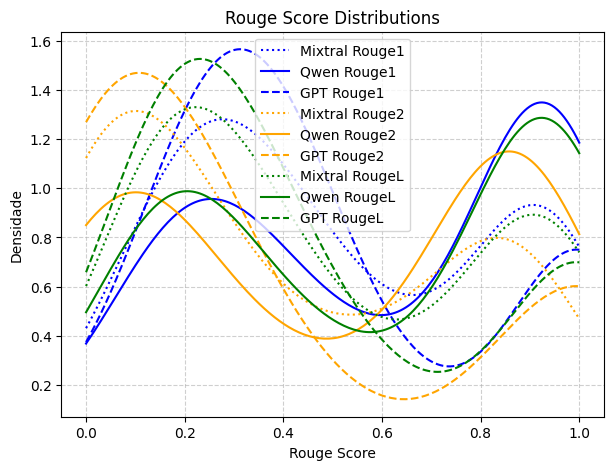

In [38]:
# Criando o gráfico
plt.figure(figsize=(7, 5))

# Estilos de linhas
sns.kdeplot(rouge_results_mixtral['rouge1'], linestyle='dotted', color='blue', label="Mixtral Rouge1", clip=(0, 1))
sns.kdeplot(rouge_results_qwen['rouge1'], linestyle='solid', color='blue', label="Qwen Rouge1", clip=(0, 1))
sns.kdeplot(rouge_results_gpt['rouge1'], linestyle='dashed', color='blue', label="GPT Rouge1", clip=(0, 1))

sns.kdeplot(rouge_results_mixtral['rouge2'], linestyle='dotted', color='orange', label="Mixtral Rouge2", clip=(0, 1))
sns.kdeplot(rouge_results_qwen['rouge2'], linestyle='solid', color='orange', label="Qwen Rouge2", clip=(0, 1))
sns.kdeplot(rouge_results_gpt['rouge2'], linestyle='dashed', color='orange', label="GPT Rouge2", clip=(0, 1))

sns.kdeplot(rouge_results_mixtral['rougeL'], linestyle='dotted', color='green', label="Mixtral RougeL", clip=(0, 1))
sns.kdeplot(rouge_results_qwen['rougeL'], linestyle='solid', color='green', label="Qwen RougeL", clip=(0, 1))
sns.kdeplot(rouge_results_gpt['rougeL'], linestyle='dashed', color='green', label="GPT RougeL", clip=(0, 1))

# Personalização
plt.xlabel("Rouge Score")
plt.ylabel("Densidade")

plt.title("Rouge Score Distributions")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Exibir gráfico
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

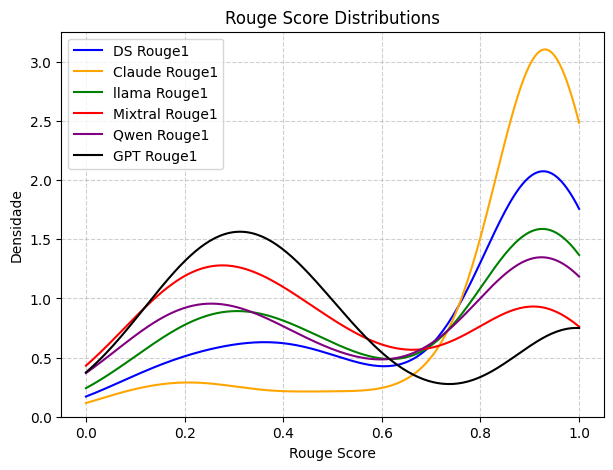

In [39]:
# Criando o gráfico
plt.figure(figsize=(7, 5))

# Estilos de linhas
sns.kdeplot(rouge_results_ds['rouge1'], linestyle='solid', color='blue', label="DS Rouge1", clip=(0, 1))
sns.kdeplot(rouge_results_claude['rouge1'], linestyle='solid', color='orange', label="Claude Rouge1", clip=(0, 1))
sns.kdeplot(rouge_results_llama['rouge1'], linestyle='solid', color='green', label="llama Rouge1", clip=(0, 1))

# Estilos de linhas
sns.kdeplot(rouge_results_mixtral['rouge1'], linestyle='solid', color='red', label="Mixtral Rouge1", clip=(0, 1))
sns.kdeplot(rouge_results_qwen['rouge1'], linestyle='solid', color='purple', label="Qwen Rouge1", clip=(0, 1))
sns.kdeplot(rouge_results_gpt['rouge1'], linestyle='solid', color='black', label="GPT Rouge1", clip=(0, 1))

# Personalização
plt.xlabel("Rouge Score")
plt.ylabel("Densidade")
plt.title("Rouge Score Distributions")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.savefig('Rouge1_OAB.png')

# Exibir gráfico
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

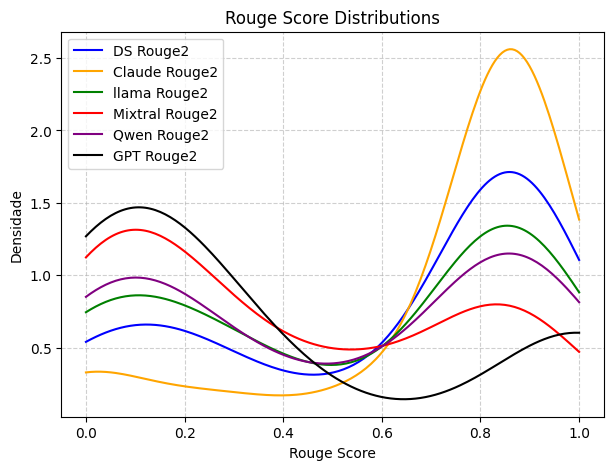

In [40]:
# Criando o gráfico
plt.figure(figsize=(7, 5))

sns.kdeplot(rouge_results_ds['rouge2'], linestyle='solid', color='blue', label="DS Rouge2", clip=(0, 1))
sns.kdeplot(rouge_results_claude['rouge2'], linestyle='solid', color='orange', label="Claude Rouge2", clip=(0, 1))
sns.kdeplot(rouge_results_llama['rouge2'], linestyle='solid', color='green', label="llama Rouge2", clip=(0, 1))

sns.kdeplot(rouge_results_mixtral['rouge2'], linestyle='solid', color='red', label="Mixtral Rouge2", clip=(0, 1))
sns.kdeplot(rouge_results_qwen['rouge2'], linestyle='solid', color='purple', label="Qwen Rouge2", clip=(0, 1))
sns.kdeplot(rouge_results_gpt['rouge2'], linestyle='solid', color='black', label="GPT Rouge2", clip=(0, 1))

# Personalização
plt.xlabel("Rouge Score")
plt.ylabel("Densidade")

plt.title("Rouge Score Distributions")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.savefig('Rouge2_OAB.png')

# Exibir gráfico
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

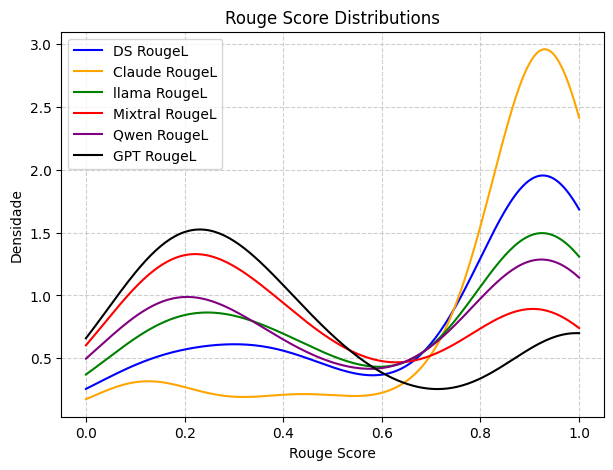

In [41]:
# Criando o gráfico
plt.figure(figsize=(7, 5))

sns.kdeplot(rouge_results_ds['rougeL'], linestyle='solid', color='blue', label="DS RougeL", clip=(0, 1))
sns.kdeplot(rouge_results_claude['rougeL'], linestyle='solid', color='orange', label="Claude RougeL", clip=(0, 1))
sns.kdeplot(rouge_results_llama['rougeL'], linestyle='solid', color='green', label="llama RougeL", clip=(0, 1))

sns.kdeplot(rouge_results_mixtral['rougeL'], linestyle='solid', color='red', label="Mixtral RougeL", clip=(0, 1))
sns.kdeplot(rouge_results_qwen['rougeL'], linestyle='solid', color='purple', label="Qwen RougeL", clip=(0, 1))
sns.kdeplot(rouge_results_gpt['rougeL'], linestyle='solid', color='black', label="GPT RougeL", clip=(0, 1))

# Personalização
plt.xlabel("Rouge Score")
plt.ylabel("Densidade")

plt.title("Rouge Score Distributions")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.savefig('RougeL_OAB.png')

# Exibir gráfico
plt.show()

In [42]:
m_rouge_results_ds = rouge.compute(predictions=predictions_ds, references=references)
m_rouge_results_claude = rouge.compute(predictions=predictions_claude, references=references)
m_rouge_results_gpt = rouge.compute(predictions=predictions_gpt, references=references)
m_rouge_results_llama = rouge.compute(predictions=predictions_llama, references=references)
m_rouge_results_mixtral = rouge.compute(predictions=predictions_mixtral, references=references)
m_rouge_results_qwen = rouge.compute(predictions=predictions_qwen, references=references)

In [43]:
m_rouge_results_ds 

{'rouge1': 0.7306308463492969,
 'rouge2': 0.6166300926152971,
 'rougeL': 0.7130897360280148,
 'rougeLsum': 0.7160143286320344}

In [44]:
m_rouge_results_claude

{'rouge1': 0.8261236627068814,
 'rouge2': 0.7370782389325514,
 'rougeL': 0.8208280619765573,
 'rougeLsum': 0.8184496712219038}

In [45]:
m_rouge_results_gpt

{'rouge1': 0.48825774191724236,
 'rouge2': 0.3443434886658047,
 'rougeL': 0.4500842965851797,
 'rougeLsum': 0.4466446225503924}

In [46]:
m_rouge_results_llama

{'rouge1': 0.6518375020943865,
 'rouge2': 0.5297234829952205,
 'rougeL': 0.6312325504254634,
 'rougeLsum': 0.6319054915995848}

In [47]:
m_rouge_results_mixtral

{'rouge1': 0.5109619317206713,
 'rouge2': 0.38139369191712524,
 'rougeL': 0.47903249203852827,
 'rougeLsum': 0.4815072776761269}

In [48]:
m_rouge_results_qwen

{'rouge1': 0.6094503494011331,
 'rouge2': 0.49587918952300797,
 'rougeL': 0.5886453609612056,
 'rougeLsum': 0.5879790530394444}

In [49]:
oab_df.opcoes.iloc[10]

['A) A Constituição da República não concede o poder de veto ao\\nChefe do Poder Executivo, por ser um instituto jurídico que\\ndesequilibraria a divisão de poderes.',
 'B) O Presidente da República pode vetar parte do projeto de Lei\\nComplementar nº XXX, mas não têm poderes para fazer o\\nmesmo em relação à proposta de Emenda Constitucional nº\\nYYY.',
 'C) O poder de veto do Presidente da República se restringe às leis\\nordinárias, logo, não poderá vetar dispositivos do projeto de\\nLei Complementar nº XXX e da proposta de Emenda\\nConstitucional nº YYY.',
 'D) Os dispositivos pertencentes ao projeto de Lei Complementar\\nnº XXX e à proposta de Emenda Constitucional nº YYY podem\\nser vetados, conforme as competências concedidas àquele que\\ndetém a Chefia do Poder Executivo.']